# Semana 12 — MLP para Classificação e Regressão de Dados Tabulares
## Arquitetura, treinamento, regularização e comparação com baseline

Na Semana 10, passamos da Random Forest para os fundamentos das redes neurais: neurônio, camadas, ativações, perda, backpropagation e escalonamento. Agora usamos esses elementos para resolver **dois tipos de problema industrial**: classificar risco de falha e estimar uma grandeza contínua.

> **Pergunta central:** como definir e avaliar uma MLP sem confundir capacidade de aprendizagem com memorização?

### Objetivos de aprendizagem

- relacionar tarefa, camada de saída e função de perda;
- construir pipelines sem vazamento de dados;
- treinar `MLPClassifier` e `MLPRegressor`;
- interpretar curvas de aprendizagem, matriz de confusão e resíduos;
- aplicar regularização L2, validação e parada antecipada;
- comparar a MLP com Random Forest usando o mesmo protocolo experimental;
- justificar a escolha do modelo pelo custo e pelo uso, não pelo nome do algoritmo.

![MLP para classificação, regressão e diagnóstico de overfitting](images/semana_12_mlp_classificacao_regressao.png)

## 1. Uma arquitetura, duas tarefas

As camadas ocultas podem ser semelhantes, mas a saída e a avaliação mudam.

| Elemento | Classificação binária | Regressão |
|---|---|---|
| alvo | classe 0/1 | número contínuo |
| saída conceitual | probabilidade | valor estimado |
| perda típica | entropia cruzada | erro quadrático |
| métricas | recall, precisão, F1, ROC-AUC | MAE, RMSE, R² |
| pergunta | “haverá falha?” | “qual será a vibração?” |

```mermaid
flowchart LR
  A[Dados brutos] --> B[Separação treino/teste]
  B --> C[Pipeline de preparação]
  C --> D[MLP]
  D --> E{Tipo de alvo}
  E -->|Categoria| F[Classificação]
  E -->|Número| G[Regressão]
  F --> H[Métricas e custo]
  G --> I[Resíduos e erro]
```

## 2. MLP sem mistério: o que a rede está tentando aprender?

Uma **MLP** (*Multilayer Perceptron*) é uma rede de neurônios organizados em camadas. Ela recebe números, combina esses números e ajusta seus pesos para que a saída fique cada vez mais próxima da resposta correta.

Imagine um técnico avaliando uma máquina. Ele observa temperatura, vibração, corrente e horas de uso. Alguns sinais recebem mais importância que outros. Um neurônio artificial faz algo semelhante:

- recebe várias medições;
- atribui um peso a cada medição;
- combina as informações;
- acrescenta um pequeno ajuste chamado **viés**;
- passa o resultado por uma função de ativação;
- envia a nova informação para a camada seguinte.

Os pesos não são definidos manualmente. Eles são ajustados durante o treinamento. Um peso maior indica que determinada entrada tem forte influência naquele neurônio, mas um peso isolado não deve ser interpretado como uma explicação completa do modelo.

### Ativações mais comuns

| Ativação | Intuição | Uso frequente |
|---|---|---|
| ReLU | valores negativos viram zero; positivos permanecem | camadas ocultas |
| Sigmoid | transforma a saída em um valor entre 0 e 1 | probabilidade binária |
| Linear | permite qualquer valor numérico | regressão |

### Como ocorre a aprendizagem?

1. A rede recebe exemplos com respostas conhecidas.
2. Produz uma previsão.
3. Compara a previsão com a resposta real.
4. Converte a diferença em uma medida de perda.
5. Identifica quais pesos mais contribuíram para o erro.
6. Corrige os pesos em pequenos passos.
7. Repete o processo durante várias épocas.

Uma **época** é uma passagem completa pelos dados de treinamento. Muitas épocas não significam automaticamente um modelo melhor: depois de certo ponto, a rede pode começar a memorizar exemplos.

### Como interpretar a saída do exemplo abaixo

- `Combinação linear` é o sinal interno produzido antes da ativação.
- `ReLU` mostra o sinal que seguiria para uma camada oculta.
- `Sigmoid/probabilidade` mostra uma saída entre 0 e 1. Um resultado `0,815`, por exemplo, pode ser lido como probabilidade estimada de 81,5% para a classe positiva — desde que o modelo esteja bem calibrado.

In [1]:
import numpy as np

def relu(z):
    return np.maximum(0, z)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Um neurônio recebe temperatura e vibração já padronizadas.
x = np.array([0.8, 1.2])
w = np.array([0.7, 1.1])
b = -0.4
z = x @ w + b

print(f"Combinação linear: {z:.3f}")
print(f"ReLU: {relu(z):.3f}")
print(f"Sigmoid/probabilidade: {sigmoid(z):.3f}")

Combinação linear: 1.480
ReLU: 1.480
Sigmoid/probabilidade: 0.815


## 3. Entropia e entropia cruzada em linguagem simples

### 3.1 Entropia: quanto existe de incerteza?

A entropia representa o grau de **incerteza** de uma situação. Pense em uma moeda:

- uma moeda equilibrada é difícil de prever; portanto, há alta incerteza;
- uma moeda que quase sempre dá cara é mais previsível; portanto, há baixa incerteza.

Em Ciência de Dados, essa ideia ajuda a representar o quanto uma distribuição está espalhada entre resultados possíveis.

### 3.2 Entropia cruzada: quanto a confiança do modelo combina com a realidade?

Na classificação binária, a rede produz uma probabilidade para a classe positiva. A entropia cruzada compara essa confiança com a resposta real.

- falha real e previsão de 95% de falha: perda pequena;
- falha real e previsão de 55%: perda intermediária;
- falha real e previsão de 1%: perda muito alta;
- operação normal e previsão de 99% de falha: perda muito alta.

O ponto mais importante é que a entropia cruzada pune fortemente previsões **confiantes e erradas**. Durante o treinamento, a MLP tenta diminuir a perda média.

### Como interpretar a tabela produzida abaixo

A coluna `perda_entropia_cruzada` não é uma porcentagem. Ela funciona como uma penalização:

- valores próximos de zero indicam previsão coerente e confiante;
- valores intermediários indicam dúvida ou confiança moderada;
- valores altos indicam que o modelo estava confiante na resposta errada.

Compare as linhas com valor real igual a `1`: conforme a probabilidade de falha cai de `0,95` para `0,01`, a perda cresce intensamente.

> **Perda não é o mesmo que métrica de negócio.** A perda orienta o ajuste dos pesos. Recall, F1 e custo financeiro ajudam a decidir se o modelo serve ao processo.

In [2]:
import pandas as pd

def entropia_cruzada_binaria(y, p, eps=1e-12):
    p = np.clip(p, eps, 1-eps)
    return -(y*np.log(p) + (1-y)*np.log(1-p))

exemplos = pd.DataFrame({
    "valor_real_y": [1, 1, 1, 0, 0],
    "probabilidade_de_falha": [0.95, 0.55, 0.01, 0.10, 0.90],
})
exemplos["perda_entropia_cruzada"] = [
    entropia_cruzada_binaria(y, p)
    for y, p in zip(exemplos.valor_real_y, exemplos.probabilidade_de_falha)
]
exemplos.round(4)

,valor_real_y,probabilidade_de_falha,perda_entropia_cruzada
0,1,0.95,0.0513
1,1,0.55,0.5978
2,1,0.01,4.6052
3,0,0.10,0.1054
4,0,0.90,2.3026


## 4. Métricas fundamentais: o que cada número responde?

### 4.1 Matriz de confusão

A matriz de confusão separa os acertos e erros conforme a classe real e a classe prevista.

| Situação | Significado industrial |
|---|---|
| verdadeiro positivo (VP) | modelo alertou e houve falha |
| falso positivo (FP) | modelo alertou, mas não houve falha |
| verdadeiro negativo (VN) | modelo não alertou e não houve falha |
| falso negativo (FN) | modelo não alertou, mas houve falha |

O falso negativo costuma ser perigoso em manutenção: uma falha real passou despercebida. O falso positivo também tem custo, pois pode provocar inspeções e paradas desnecessárias.

### 4.2 Acurácia

É a proporção total de previsões corretas. Pode enganar em classes desbalanceadas: se apenas 2% das máquinas falham, um modelo que sempre diz “normal” alcança 98% de acurácia e não detecta nenhuma falha.

### 4.3 Precisão

Responde: **entre os alertas emitidos, quantos estavam corretos?**

Precisão alta significa poucos alarmes falsos. É relevante quando investigar um alerta custa caro.

### 4.4 Recall ou sensibilidade

Responde: **entre todas as falhas que realmente aconteceram, quantas foram detectadas?**

Recall alto significa poucas falhas ignoradas. É relevante quando deixar de antecipar uma falha é muito caro ou perigoso.

### 4.5 F1-score

Resume o equilíbrio entre precisão e recall. Só fica alto quando os dois indicadores apresentam resultados razoáveis. Ainda assim, sempre examine precisão e recall separadamente para saber qual tipo de erro está ocorrendo.

### 4.6 ROC-AUC

Avalia a capacidade do modelo de colocar exemplos de maior risco acima dos de menor risco ao considerar vários limiares.

- próximo de `1,0`: excelente separação;
- próximo de `0,5`: comportamento semelhante ao acaso;
- abaixo de `0,5`: ordenação invertida ou possível problema de implementação.

ROC-AUC não escolhe sozinho o limiar operacional. Para eventos muito raros, a curva precisão-recall pode ser mais informativa.

### Como interpretar a saída do exemplo abaixo

O exemplo utiliza 20 verdadeiros positivos, 10 falsos positivos, 65 verdadeiros negativos e 5 falsos negativos.

- a acurácia resume todos os acertos, mas mistura as duas classes;
- a precisão mostra o grau de confiança nos alertas emitidos;
- o recall mostra a cobertura das falhas reais;
- o F1 diminui se precisão ou recall estiver baixa.

Não procure apenas o maior número: pergunte qual erro o processo industrial tolera menos.

In [3]:
def metricas_da_matriz(vp, fp, vn, fn):
    acuracia = (vp+vn)/(vp+fp+vn+fn)
    precisao = vp/(vp+fp) if vp+fp else 0
    recall = vp/(vp+fn) if vp+fn else 0
    f1 = 2*precisao*recall/(precisao+recall) if precisao+recall else 0
    return {"acurácia":acuracia, "precisão":precisao, "recall":recall, "F1":f1}

# 20 falhas detectadas, 10 alarmes falsos, 65 normais corretas e 5 falhas perdidas.
pd.Series(metricas_da_matriz(vp=20, fp=10, vn=65, fn=5)).round(3)

acurácia    0.850
precisão    0.667
recall      0.800
F1          0.727
dtype: float64

### 4.7 Métricas de regressão: MAE, MSE, RMSE e R²

Na regressão, o modelo prevê um número, como temperatura futura ou intensidade de vibração. O erro é a distância entre o valor real e o previsto. Como erros para cima e para baixo poderiam se cancelar, as métricas tratam essas distâncias antes de calcular uma média.

### MAE — erro absoluto médio

Representa a distância média entre previsões e valores reais, ignorando o sinal do erro.

Se o MAE da vibração for `0,30 mm/s`, podemos dizer que as previsões erram, em média, aproximadamente `0,30 mm/s`. É fácil de interpretar e não aumenta excessivamente o peso de poucos erros extremos.

### MSE — erro quadrático médio

Antes de calcular a média, aumenta bastante a influência dos erros grandes. Assim, errar por 4 unidades pesa muito mais que errar por 1 unidade.

É útil no treinamento porque incentiva a rede a evitar grandes desvios. Sua desvantagem didática é ficar em unidade ao quadrado, o que dificulta a interpretação direta.

### RMSE — raiz do erro quadrático médio

Mantém a maior penalização dos erros grandes, mas retorna à unidade original do alvo. Quando o RMSE fica muito maior que o MAE, provavelmente existem alguns erros extremos afetando o modelo.

### R² — coeficiente de determinação

Compara o modelo com uma estratégia muito simples: prever sempre a média dos valores observados.

- `R² = 1`: previsões perfeitas;
- `R² = 0`: o modelo não melhora a previsão constante da média;
- `R² < 0`: o modelo está pior que simplesmente usar a média;
- `R² = 0,80`: no conjunto avaliado, o modelo representa aproximadamente 80% da variação observada.

R² não informa o tamanho do erro na unidade real e não prova relação de causa e efeito. Por isso, deve ser acompanhado por MAE, RMSE e análise dos resíduos.

### Como interpretar a saída do exemplo abaixo

O exemplo compara quatro valores reais com quatro previsões.

- `MAE` mostra o erro típico de forma direta;
- `MSE` aparece maior porque enfatiza o erro mais distante;
- `RMSE` volta à unidade original e permanece sensível ao erro grande;
- `R²` informa se o conjunto de previsões melhora a referência baseada na média.

Depois, no modelo industrial completo, interprete `MAE = 0,299` como erro absoluto médio de aproximadamente `0,30` unidade de vibração, `RMSE = 0,365` como evidência de alguma influência adicional dos erros maiores e `R² = 0,827` como boa representação da variação do alvo naquele conjunto de teste.

In [4]:
reais = np.array([10.0, 12.0, 14.0, 16.0])
previstos = np.array([9.0, 15.0, 13.0, 15.0])
erros = reais - previstos
mae_manual = np.mean(np.abs(erros))
mse_manual = np.mean(erros**2)
rmse_manual = np.sqrt(mse_manual)
r2_manual = 1 - np.sum(erros**2)/np.sum((reais-reais.mean())**2)

pd.Series({
    "MAE": mae_manual,
    "MSE": mse_manual,
    "RMSE": rmse_manual,
    "R²": r2_manual,
}).round(3)

MAE     1.500
MSE     3.000
RMSE    1.732
R²      0.400
dtype: float64

### Mapa rápido de escolha

| Pergunta | Métrica útil |
|---|---|
| quantos alertas estavam certos? | precisão |
| quantas falhas reais detectamos? | recall |
| quero equilibrar precisão e recall | F1 |
| o modelo ordena bem o risco em vários limiares? | ROC-AUC |
| qual o erro médio na unidade original? | MAE |
| erros grandes devem pesar muito? | MSE/RMSE |
| quanto melhoramos em relação à média? | R² |

Nenhuma métrica é universal. A escolha depende do custo do erro e da decisão que será tomada.

## 5. Dados industriais sintéticos

O conjunto representa leituras agregadas de motores. A classe `falha_24h` indica risco nas próximas 24 horas; `vibracao_futura` é uma meta contínua. A simulação permite conhecer as relações geradoras, mas o protocolo é o mesmo para dados reais.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(12)
n = 1200
df = pd.DataFrame({
    "temperatura": rng.normal(68, 8, n),
    "vibracao": rng.gamma(2.3, 1.0, n),
    "corrente": rng.normal(41, 6, n),
    "pressao": rng.normal(6.1, 0.65, n),
    "horas_operacao": rng.uniform(100, 8000, n),
})
logit = (-4.4 + .055*(df.temperatura-60) + .65*df.vibracao
         + .00022*df.horas_operacao + .7*((df.temperatura>76)&(df.vibracao>3.5)))
prob = 1/(1+np.exp(-logit))
df["falha_24h"] = rng.binomial(1, prob)
df["vibracao_futura"] = (0.45*df.vibracao + .035*(df.temperatura-60)
                           + .00008*df.horas_operacao + rng.normal(0,.35,n))
df.head()

,temperatura,vibracao,corrente,pressao,horas_operacao,falha_24h,vibracao_futura
0,67.945386,1.329754,41.857838,5.813696,6516.318037,0,1.718174
1,76.369146,0.843609,48.216398,6.071904,1001.889813,0,0.926089
2,73.932707,1.664450,42.387848,4.803432,103.235003,0,1.264336
3,73.791652,1.154044,40.522194,6.682569,5984.151411,0,0.725308
4,80.950210,6.995388,37.494764,7.312180,2412.737075,1,4.119723


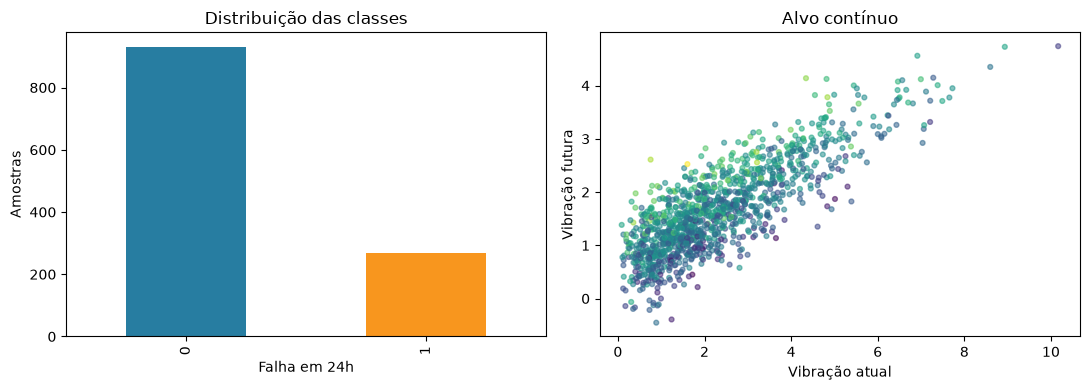

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df.falha_24h.value_counts().sort_index().plot.bar(ax=ax[0], color=["#277da1","#f8961e"])
ax[0].set(title="Distribuição das classes", xlabel="Falha em 24h", ylabel="Amostras")
ax[1].scatter(df.vibracao, df.vibracao_futura, c=df.temperatura, s=12, alpha=.55, cmap="viridis")
ax[1].set(title="Alvo contínuo", xlabel="Vibração atual", ylabel="Vibração futura")
plt.tight_layout()

## 6. Pipeline e prevenção de vazamento

O `StandardScaler` aprende média e desvio apenas com o treino quando está dentro do `Pipeline`. O teste permanece uma aproximação de dados futuros. A estratificação preserva a proporção da classe no problema de classificação.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier, MLPRegressor

features = ["temperatura","vibracao","corrente","pressao","horas_operacao"]
X = df[features]
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(X, df.falha_24h, test_size=.25, random_state=42, stratify=df.falha_24h)
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(X, df.vibracao_futura, test_size=.25, random_state=42)

clf = Pipeline([("escala",StandardScaler()),("mlp",MLPClassifier(hidden_layer_sizes=(24,12), alpha=.001, early_stopping=True, max_iter=600, random_state=42))])
reg = Pipeline([("escala",StandardScaler()),("mlp",MLPRegressor(hidden_layer_sizes=(24,12), alpha=.001, early_stopping=True, max_iter=600, random_state=42))])
clf.fit(Xc_tr,yc_tr); reg.fit(Xr_tr,yr_tr)
print("Épocas classificação:", clf.named_steps["mlp"].n_iter_)
print("Épocas regressão:", reg.named_steps["mlp"].n_iter_)

Épocas classificação: 23
Épocas regressão: 109


## 7. Avaliação da classificação

Acurácia isolada pode esconder falhas não detectadas. Observe matriz de confusão, recall da classe positiva, F1 e ROC-AUC. O limiar padrão de 0,5 é uma decisão operacional ajustável.

              precision    recall  f1-score   support

           0      0.810     0.987     0.890       233
           1      0.812     0.194     0.313        67

    accuracy                          0.810       300
   macro avg      0.811     0.591     0.602       300
weighted avg      0.810     0.810     0.761       300

ROC-AUC: 0.777


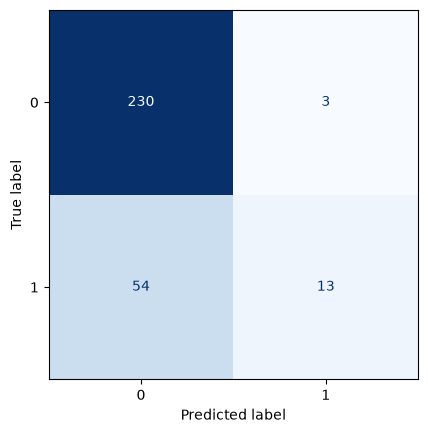

In [8]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, roc_auc_score
pred_c=clf.predict(Xc_te); prob_c=clf.predict_proba(Xc_te)[:,1]
print(classification_report(yc_te,pred_c,digits=3,zero_division=0))
print("ROC-AUC:",round(roc_auc_score(yc_te,prob_c),3))
ConfusionMatrixDisplay.from_predictions(yc_te,pred_c,cmap="Blues",colorbar=False)

In [9]:
from sklearn.metrics import precision_score, recall_score, f1_score
linhas=[]
for t in [.25,.35,.50,.65,.75]:
    p=(prob_c>=t).astype(int)
    linhas.append({"limiar":t,"precisão":precision_score(yc_te,p,zero_division=0),"recall":recall_score(yc_te,p,zero_division=0),"F1":f1_score(yc_te,p,zero_division=0)})
pd.DataFrame(linhas).round(3)

,limiar,precisão,recall,F1
0,0.25,0.377,0.821,0.516
1,0.35,0.465,0.493,0.478
2,0.50,0.812,0.194,0.313
3,0.65,0.000,0.000,0.000
4,0.75,0.000,0.000,0.000


## 8. Avaliação da regressão

- **MAE:** erro absoluto médio, fácil de explicar na unidade do alvo.
- **RMSE:** penaliza erros grandes com mais intensidade.
- **R²:** fração da variabilidade explicada em relação a prever a média.

Resíduos com padrão indicam informação não aprendida ou premissa inadequada.

MAE: 0.299
RMSE: 0.365
R²: 0.827


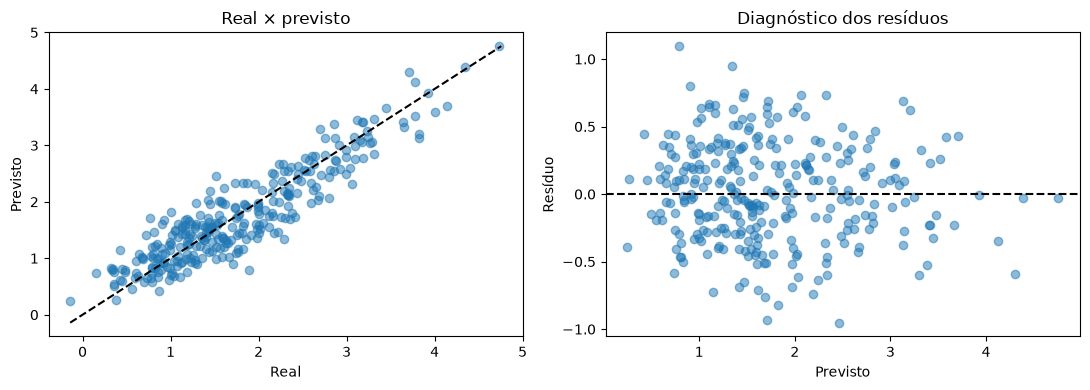

In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
pred_r=reg.predict(Xr_te); residuos=yr_te-pred_r
print("MAE:",round(mean_absolute_error(yr_te,pred_r),3))
print("RMSE:",round(mean_squared_error(yr_te,pred_r)**.5,3))
print("R²:",round(r2_score(yr_te,pred_r),3))
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].scatter(yr_te,pred_r,alpha=.5); lim=[min(yr_te.min(),pred_r.min()),max(yr_te.max(),pred_r.max())]; ax[0].plot(lim,lim,"--",color="black"); ax[0].set(xlabel="Real",ylabel="Previsto",title="Real × previsto")
ax[1].scatter(pred_r,residuos,alpha=.5); ax[1].axhline(0,color="black",ls="--"); ax[1].set(xlabel="Previsto",ylabel="Resíduo",title="Diagnóstico dos resíduos")
plt.tight_layout()

## 9. Regularização e overfitting

`alpha` controla a penalização L2: pesos muito grandes passam a custar mais. `early_stopping` separa parte do treino para validação e interrompe quando a melhora deixa de ser relevante. Redes maiores aumentam capacidade, mas também variância, custo e dificuldade de explicar.

```mermaid
flowchart TD
 A[Erro alto em treino e validação] --> B[Underfitting]
 C[Erro de treino cai; validação piora] --> D[Overfitting]
 E[Ambos caem e estabilizam] --> F[Generalização plausível]
 D --> G[Mais regularização / menos camadas / mais dados]
 B --> H[Mais capacidade / melhores atributos / mais treino]
```

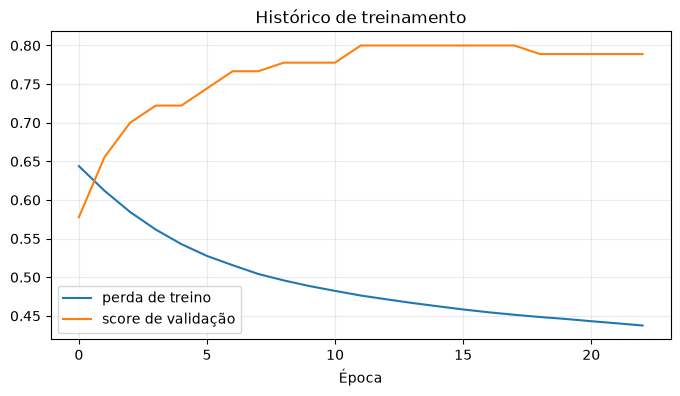

In [11]:
m=clf.named_steps["mlp"]
plt.figure(figsize=(8,4)); plt.plot(m.loss_curve_,label="perda de treino")
if hasattr(m,"validation_scores_") and m.validation_scores_ is not None:
    plt.plot(m.validation_scores_,label="score de validação")
plt.xlabel("Época"); plt.title("Histórico de treinamento"); plt.grid(alpha=.25); plt.legend()

## 10. Comparação justa com Random Forest

O baseline usa exatamente a mesma divisão. Se os desempenhos forem próximos, entram na decisão latência, manutenção, explicabilidade e estabilidade.

In [12]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
rf_c=RandomForestClassifier(n_estimators=250,class_weight="balanced",random_state=42).fit(Xc_tr,yc_tr)
rf_r=RandomForestRegressor(n_estimators=250,random_state=42).fit(Xr_tr,yr_tr)
comparacao=pd.DataFrame([
 {"modelo":"MLP classificação","métrica":"ROC-AUC","valor":roc_auc_score(yc_te,prob_c)},
 {"modelo":"RF classificação","métrica":"ROC-AUC","valor":roc_auc_score(yc_te,rf_c.predict_proba(Xc_te)[:,1])},
 {"modelo":"MLP regressão","métrica":"MAE","valor":mean_absolute_error(yr_te,pred_r)},
 {"modelo":"RF regressão","métrica":"MAE","valor":mean_absolute_error(yr_te,rf_r.predict(Xr_te))},
])
comparacao.round(3)

,modelo,métrica,valor
0,MLP classificação,ROC-AUC,0.777
1,RF classificação,ROC-AUC,0.771
2,MLP regressão,MAE,0.299
3,RF regressão,MAE,0.309


## 11. Exercícios práticos

### Exercício 1 — Arquitetura controlada
Treine `(8,)`, `(24,12)` e `(48,24,12)`. Registre épocas, ROC-AUC, recall e tempo. Explique capacidade × generalização.

### Exercício 2 — Regularização
Compare `alpha` em `0.0001`, `0.01` e `0.1`. Examine perda e validação; não escolha apenas pela métrica final.

### Exercício 3 — Custo assimétrico
Adote custo 8 para falso negativo e 1 para falso positivo. Encontre o limiar de menor custo no teste e justifique.

### Exercício 4 — Regressão e resíduos
Crie `temperatura²` e interação `temperatura × vibracao`. Verifique se MAE e padrão residual mudam.

### Exercício 5 — Decisão CRISP-DM
Produza uma tabela MLP × Random Forest incluindo desempenho, latência, explicabilidade, manutenção e risco. Recomende um modelo.

**Entregável:** notebook executado, tabela comparativa e conclusão de até 300 palavras.

## Bibliografia

- GOODFELLOW, I.; BENGIO, Y.; COURVILLE, A. *Deep Learning*. MIT Press, 2016. <https://www.deeplearningbook.org/>.
- GÉRON, A. *Hands-On Machine Learning with Scikit-Learn, Keras & TensorFlow*. 3. ed. O'Reilly, 2022.
- SCIKIT-LEARN. **MLPClassifier**. <https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html>.
- SCIKIT-LEARN. **MLPRegressor**. <https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPRegressor.html>.
- SCIKIT-LEARN. **Common pitfalls and recommended practices**. <https://scikit-learn.org/stable/common_pitfalls.html>.